<a href="https://colab.research.google.com/github/mamontoff2018-lgtm/google-colab/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22MO9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

100%|██████████| 792M/792M [00:46<00:00, 17.0MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.1MB/s]


Всего изображений: 3680
Train: 2944 | Val: 736
Классов (пород): 37

Таблица: Класс — Число примеров (первые 10 классов)
ID   | Название класса      | Примеров
----------------------------------------
0    | Abyssinian           | 100     
1    | American Bulldog     | 100     
2    | American Pit Bull Terrier | 100     
3    | Basset Hound         | 100     
4    | Beagle               | 100     
5    | Bengal               | 100     
6    | Birman               | 100     
7    | Bombay               | 96      
8    | Boxer                | 100     
9    | British Shorthair    | 100     


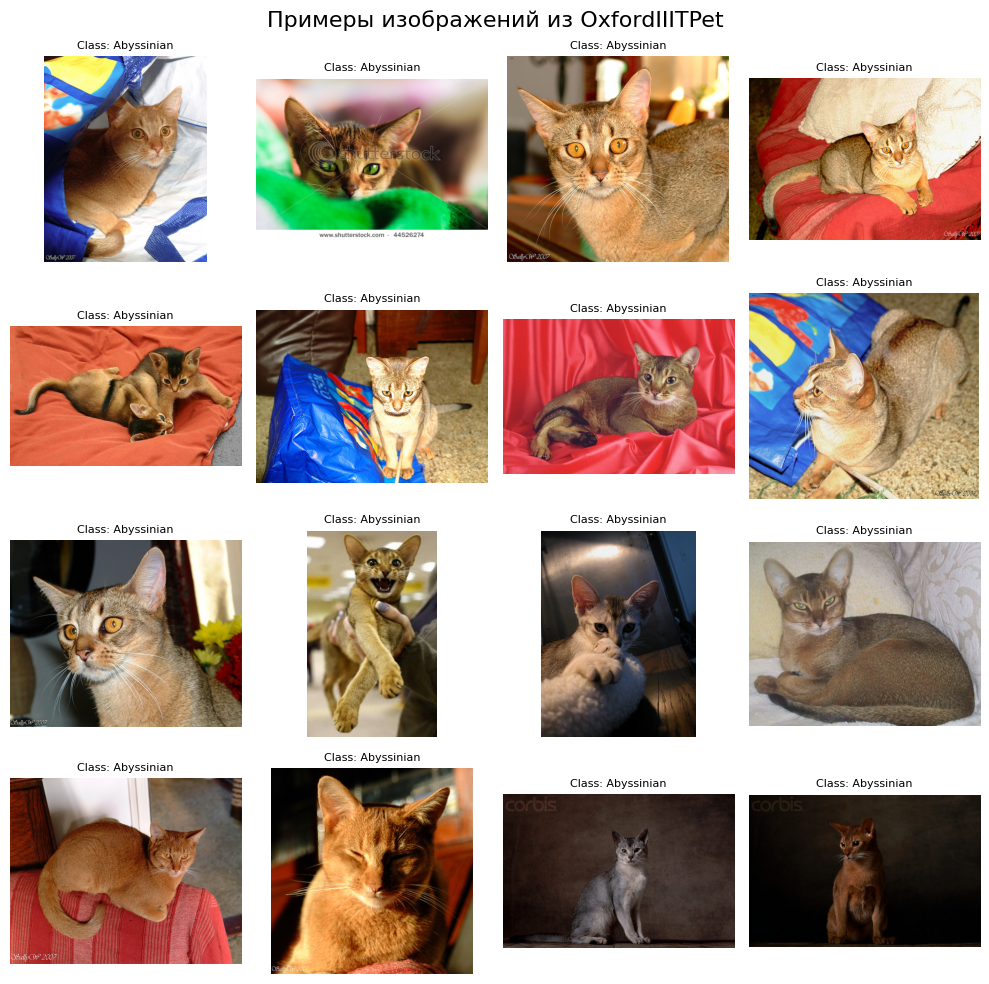

In [1]:
import torch
import torchvision
from torchvision import transforms as T, datasets
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import collections
# 1. Трансформации (Normalize использует статистики ImageNet для ResNet-18)
IMNET_MEAN = (0.485, 0.456, 0.406)
IMNET_STD = (0.229, 0.224, 0.225)
train_tf = T.Compose([
    T.RandomResizedCrop(224, scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(IMNET_MEAN, IMNET_STD),
])

val_tf = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(IMNET_MEAN, IMNET_STD),
])
# Загружаем сырой датасет , без нормализации
raw_dataset = datasets.OxfordIIITPet(
    root='./data',
    split='trainval',
    download=True,
    transform=T.ToTensor()
)
# 2. Разделение
train_size = int(0.8 * len(raw_dataset))
val_size = len(raw_dataset) - train_size
generator = torch.Generator().manual_seed(42)
train_indices, val_indices = random_split(range(len(raw_dataset)), [train_size, val_size], generator=generator)
train_ds = torch.utils.data.Subset(datasets.OxfordIIITPet('./data', split='trainval', download=False, transform=train_tf), train_indices)
val_ds = torch.utils.data.Subset(datasets.OxfordIIITPet('./data', split='trainval', download=False, transform=val_tf), val_indices)
print(f"Всего изображений: {len(raw_dataset)}")
print(f"Train: {len(train_ds)} | Val: {len(val_ds)}")
print(f"Классов (пород): {len(raw_dataset.classes)}")
# 3. Таблица «Класс — Число примеров»
targets = raw_dataset._labels
class_counts = collections.Counter(targets)
print("\nТаблица: Класс — Число примеров (первые 10 классов)")
print(f"{'ID':<4} | {'Название класса':<20} | {'Примеров':<8}")
print("-" * 40)
for i in range(10): # Выводим первые 10 для примера, чтобы не засорять консоль
    class_name = raw_dataset.classes[i]
    print(f"{i:<4} | {class_name:<20} | {class_counts[i]:<8}")
# 4. Сетка 4х4 примеров (ДО нормализации)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle("Примеры изображений из OxfordIIITPet", fontsize=16)
for i, ax in enumerate(axes.flat):
    img, label = raw_dataset[i]
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(f"Class: {raw_dataset.classes[label]}", fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=2)

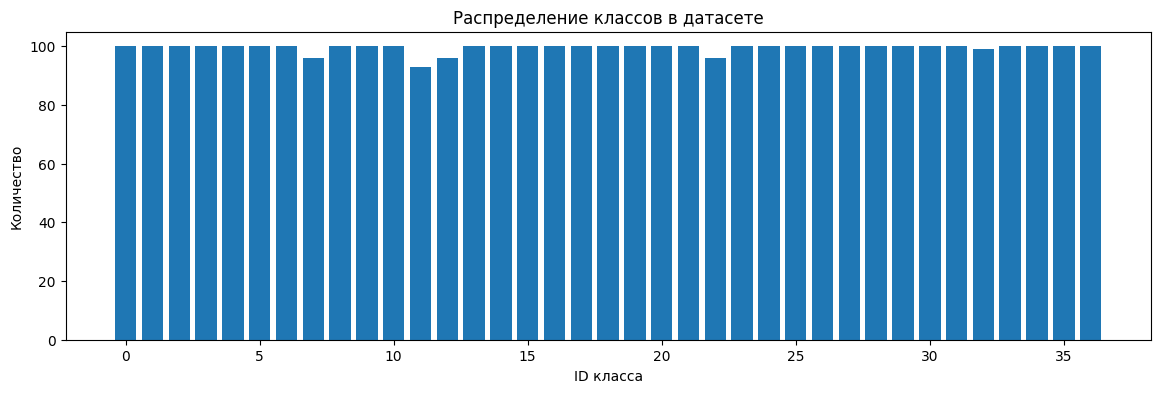

In [16]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 4))
plt.bar(range(37), [class_counts[i] for i in range(37)])
plt.title('Распределение классов в датасете')
plt.xlabel('ID класса')
plt.ylabel('Количество')
plt.show()

In [2]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights
# 1. Загружаем предобученную ResNet-18
weights = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=weights)
print(model)
# 2. Получаем значение in_features для последнего слоя
in_features = model.fc.in_features
print(f"\nЗначение model.fc.in_features: {in_features}")
# 3. Выводим таблицу с параметрами по модулям
print("\nТаблица: Параметры по модулям ResNet-18")
print(f"{'Модуль':<12} | {'Параметров':<12} | {'Доля от всех':<12}")
print("-" * 42)
total_params = sum(p.numel() for p in model.parameters())
for name, module in model.named_children():
    if name == 'avgpool': continue # У пулинга нет параметров
    params = sum(p.numel() for p in module.parameters())
    percent = (params / total_params) * 100
    print(f"{name:<12} | {params:<12,} | {percent:>6.1f}%")
print("-" * 42)
print(f"{'ИТОГО':<12} | {total_params:<12,} | 100.0%")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 197MB/s]

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [3]:
NUM_CLASSES = 37
# Заменяем старую голову на 1000 классов (ImageNet) на новую для 37 пород
model.fc = nn.Linear(in_features, NUM_CLASSES)
print("Новая структура головы модели:")
print(model.fc)
# Считаем параметры после замены
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
head_params = sum(p.numel() for p in model.fc.parameters())
print(f"\nОбщее число параметров: {total_params:,}")
print(f"Число параметров в новой голове (fc): {head_params:,}")
print(f"Доля головы от всех параметров: {100 * head_params / total_params:.2f}%")

Новая структура головы модели:
Linear(in_features=512, out_features=37, bias=True)

Общее число параметров: 11,195,493
Число параметров в новой голове (fc): 18,981
Доля головы от всех параметров: 0.17%


In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
import time
from torchvision.models import resnet18, ResNet18_Weights
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Используем устройство: {device}")
# 1. Создаем модель заново
model_a = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
model_a.fc = nn.Linear(512, 37)
model_a = model_a.to(device)
# 2. ЗАМОРАЖИВАЕМ всё, кроме головы
for param in model_a.parameters():
    param.requires_grad = False
for param in model_a.fc.parameters():
    param.requires_grad = True
trainable_params = sum(p.numel() for p in model_a.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model_a.parameters())
print(f"Обучаемых параметров (Эксперимент A): {trainable_params:,} ({100 * trainable_params / total_params:.2f}%)")
# 3. Оптимизатор для 13 варианта
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model_a.parameters()),
                        lr=1e-4, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
# 4. Функции для обучения и оценки
def train_epoch(model, loader, opt, crit):
    model.train()
    loss_sum, correct, total = 0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        out = model(xb)
        loss = crit(out, yb)
        loss.backward()
        opt.step()
        loss_sum += loss.item() * yb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return loss_sum / total, correct / total
def evaluate(model, loader, crit):
    model.eval()
    loss_sum, correct, total = 0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = crit(out, yb)
            loss_sum += loss.item() * yb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.size(0)
    return loss_sum / total, correct / total
# 5. Цикл обучения
EPOCHS = 5
print(f"\nНачинаем Feature Extraction (только голова) на {EPOCHS} эпох...")
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_epoch(model_a, train_dl, optimizer, criterion)
    val_loss, val_acc = evaluate(model_a, val_dl, criterion)
    epoch_time = time.time() - t0
    print(f"Эпоха {epoch:02d}/{EPOCHS} | "
          f"Train Loss: {tr_loss:.4f} Acc: {tr_acc:.3f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.3f} | "
          f"Время: {epoch_time:.1f} сек")

Используем устройство: cuda
Обучаемых параметров (Эксперимент A): 18,981 (0.17%)

Начинаем Feature Extraction (только голова) на 5 эпох...
Эпоха 01/5 | Train Loss: 3.4226 Acc: 0.114 | Val Loss: 3.1100 Acc: 0.227 | Время: 22.6 сек
Эпоха 02/5 | Train Loss: 2.8844 Acc: 0.334 | Val Loss: 2.6211 Acc: 0.431 | Время: 20.7 сек
Эпоха 03/5 | Train Loss: 2.4558 Acc: 0.538 | Val Loss: 2.2060 Acc: 0.595 | Время: 23.3 сек
Эпоха 04/5 | Train Loss: 2.1020 Acc: 0.655 | Val Loss: 1.8971 Acc: 0.689 | Время: 19.1 сек
Эпоха 05/5 | Train Loss: 1.8165 Acc: 0.740 | Val Loss: 1.6383 Acc: 0.749 | Время: 20.4 сек


In [6]:
import torch.optim as optim
import time
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights
# Создаем модель заново
model_ft = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
model_ft.fc = nn.Linear(512, 37)
model_ft = model_ft.to(device)
# Замораживаем всё
for param in model_ft.parameters():
    param.requires_grad = False
# Размораживаем layer3, layer4, fc
for name, child in model_ft.named_children():
    if name in ['layer3', 'layer4', 'fc']:
        for param in child.parameters():
            param.requires_grad = True
# Оптимизатор AdamW с разными LR
optimizer_ft = optim.AdamW([
    {'params': model_ft.layer3.parameters(), 'lr': 5e-5},
    {'params': model_ft.layer4.parameters(), 'lr': 1e-4},
    {'params': model_ft.fc.parameters(),     'lr': 5e-4}
], weight_decay=1e-4)
EPOCHS = 15
scheduler_ft = optim.lr_scheduler.CosineAnnealingLR(optimizer_ft, T_max=EPOCHS)
criterion = nn.CrossEntropyLoss()
history_ft = {'tr_loss': [], 'tr_acc': [], 'va_loss': [], 'va_acc': []}
print("Эксперимент B: Fine-tuning")
for epoch in range(1, EPOCHS + 1):
    tr_l, tr_a = train_epoch(model_ft, train_dl, optimizer_ft, criterion)
    va_l, va_a = evaluate(model_ft, val_dl, criterion)
    scheduler_ft.step()
    history_ft['tr_loss'].append(tr_l)
    history_ft['tr_acc'].append(tr_a)
    history_ft['va_loss'].append(va_l)
    history_ft['va_acc'].append(va_a)
    print(f"Эпоха {epoch:02d}/{EPOCHS} | Val Acc: {va_a:.4f}")

Эксперимент B: Fine-tuning
Эпоха 01/15 | Val Acc: 0.8804
Эпоха 02/15 | Val Acc: 0.8967
Эпоха 03/15 | Val Acc: 0.9117
Эпоха 04/15 | Val Acc: 0.9171
Эпоха 05/15 | Val Acc: 0.9171
Эпоха 06/15 | Val Acc: 0.9266
Эпоха 07/15 | Val Acc: 0.9185
Эпоха 08/15 | Val Acc: 0.9253
Эпоха 09/15 | Val Acc: 0.9375
Эпоха 10/15 | Val Acc: 0.9293
Эпоха 11/15 | Val Acc: 0.9280
Эпоха 12/15 | Val Acc: 0.9293
Эпоха 13/15 | Val Acc: 0.9307
Эпоха 14/15 | Val Acc: 0.9253
Эпоха 15/15 | Val Acc: 0.9239


In [7]:
model_scratch = resnet18(weights=None)
model_scratch.fc = nn.Linear(512, 37)
model_scratch = model_scratch.to(device)
optimizer_scratch = optim.AdamW(model_scratch.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_scratch = optim.lr_scheduler.CosineAnnealingLR(optimizer_scratch, T_max=EPOCHS)
history_scratch = {'tr_loss': [], 'tr_acc': [], 'va_loss': [], 'va_acc': []}
print("Эксперимент C: С нуля (Scratch)")
for epoch in range(1, EPOCHS + 1):
    tr_l, tr_a = train_epoch(model_scratch, train_dl, optimizer_scratch, criterion)
    va_l, va_a = evaluate(model_scratch, val_dl, criterion)
    scheduler_scratch.step()
    history_scratch['tr_loss'].append(tr_l)
    history_scratch['tr_acc'].append(tr_a)
    history_scratch['va_loss'].append(va_l)
    history_scratch['va_acc'].append(va_a)
    print(f"Эпоха {epoch:02d}/{EPOCHS} | Val Acc: {va_a:.4f}")

Эксперимент C: С нуля (Scratch)
Эпоха 01/15 | Val Acc: 0.0571
Эпоха 02/15 | Val Acc: 0.0774
Эпоха 03/15 | Val Acc: 0.1046
Эпоха 04/15 | Val Acc: 0.1277
Эпоха 05/15 | Val Acc: 0.1590
Эпоха 06/15 | Val Acc: 0.1617
Эпоха 07/15 | Val Acc: 0.2079
Эпоха 08/15 | Val Acc: 0.2065
Эпоха 09/15 | Val Acc: 0.2459
Эпоха 10/15 | Val Acc: 0.3030
Эпоха 11/15 | Val Acc: 0.3030
Эпоха 12/15 | Val Acc: 0.3247
Эпоха 13/15 | Val Acc: 0.3587
Эпоха 14/15 | Val Acc: 0.3859
Эпоха 15/15 | Val Acc: 0.3750


In [9]:
# Быстрое обучение Feature Extraction (3 эпохи) для графика
import torch.optim as optim
model_fe = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
model_fe.fc = nn.Linear(512, 37)
model_fe = model_fe.to(device)
for param in model_fe.parameters(): param.requires_grad = False
for param in model_fe.fc.parameters(): param.requires_grad = True
optimizer_fe = optim.AdamW(filter(lambda p: p.requires_grad, model_fe.parameters()), lr=1e-4, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()
history_fe = {'va_acc': []}
print("Быстрое обучение Feature Extraction (3 эпохи)...")
for epoch in range(3):
    train_epoch(model_fe, train_dl, optimizer_fe, criterion)
    _, va_a = evaluate(model_fe, val_dl, criterion)
    history_fe['va_acc'].append(va_a)
    print(f"Эпоха {epoch+1} | Val Acc: {va_a:.4f}")

Быстрое обучение Feature Extraction (3 эпохи)...
Эпоха 1 | Val Acc: 0.2459
Эпоха 2 | Val Acc: 0.4959
Эпоха 3 | Val Acc: 0.6196


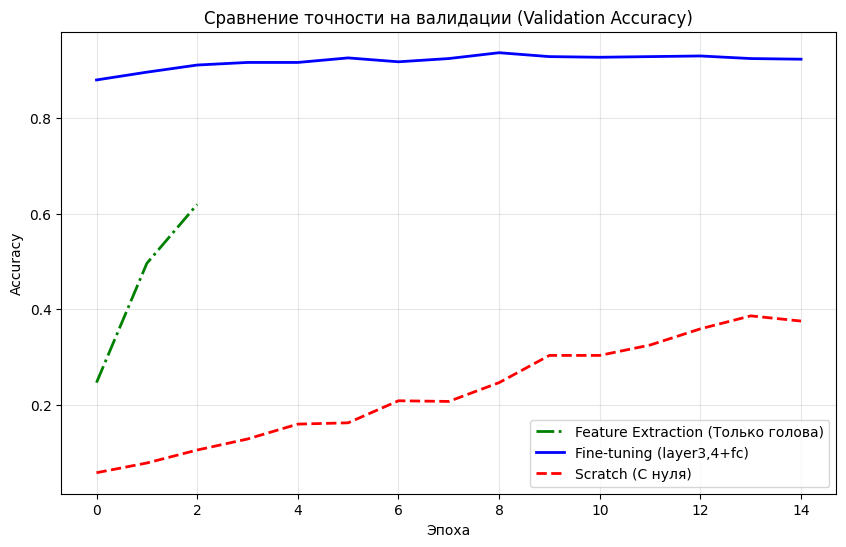

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(history_fe['va_acc'], label='Feature Extraction (Только голова)', color='green', linestyle='-.', linewidth=2)
plt.plot(history_ft['va_acc'], label='Fine-tuning (layer3,4+fc)', color='blue', linewidth=2)
plt.plot(history_scratch['va_acc'], label='Scratch (С нуля)', color='red', linestyle='--', linewidth=2)
plt.title('Сравнение точности на валидации (Validation Accuracy)')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

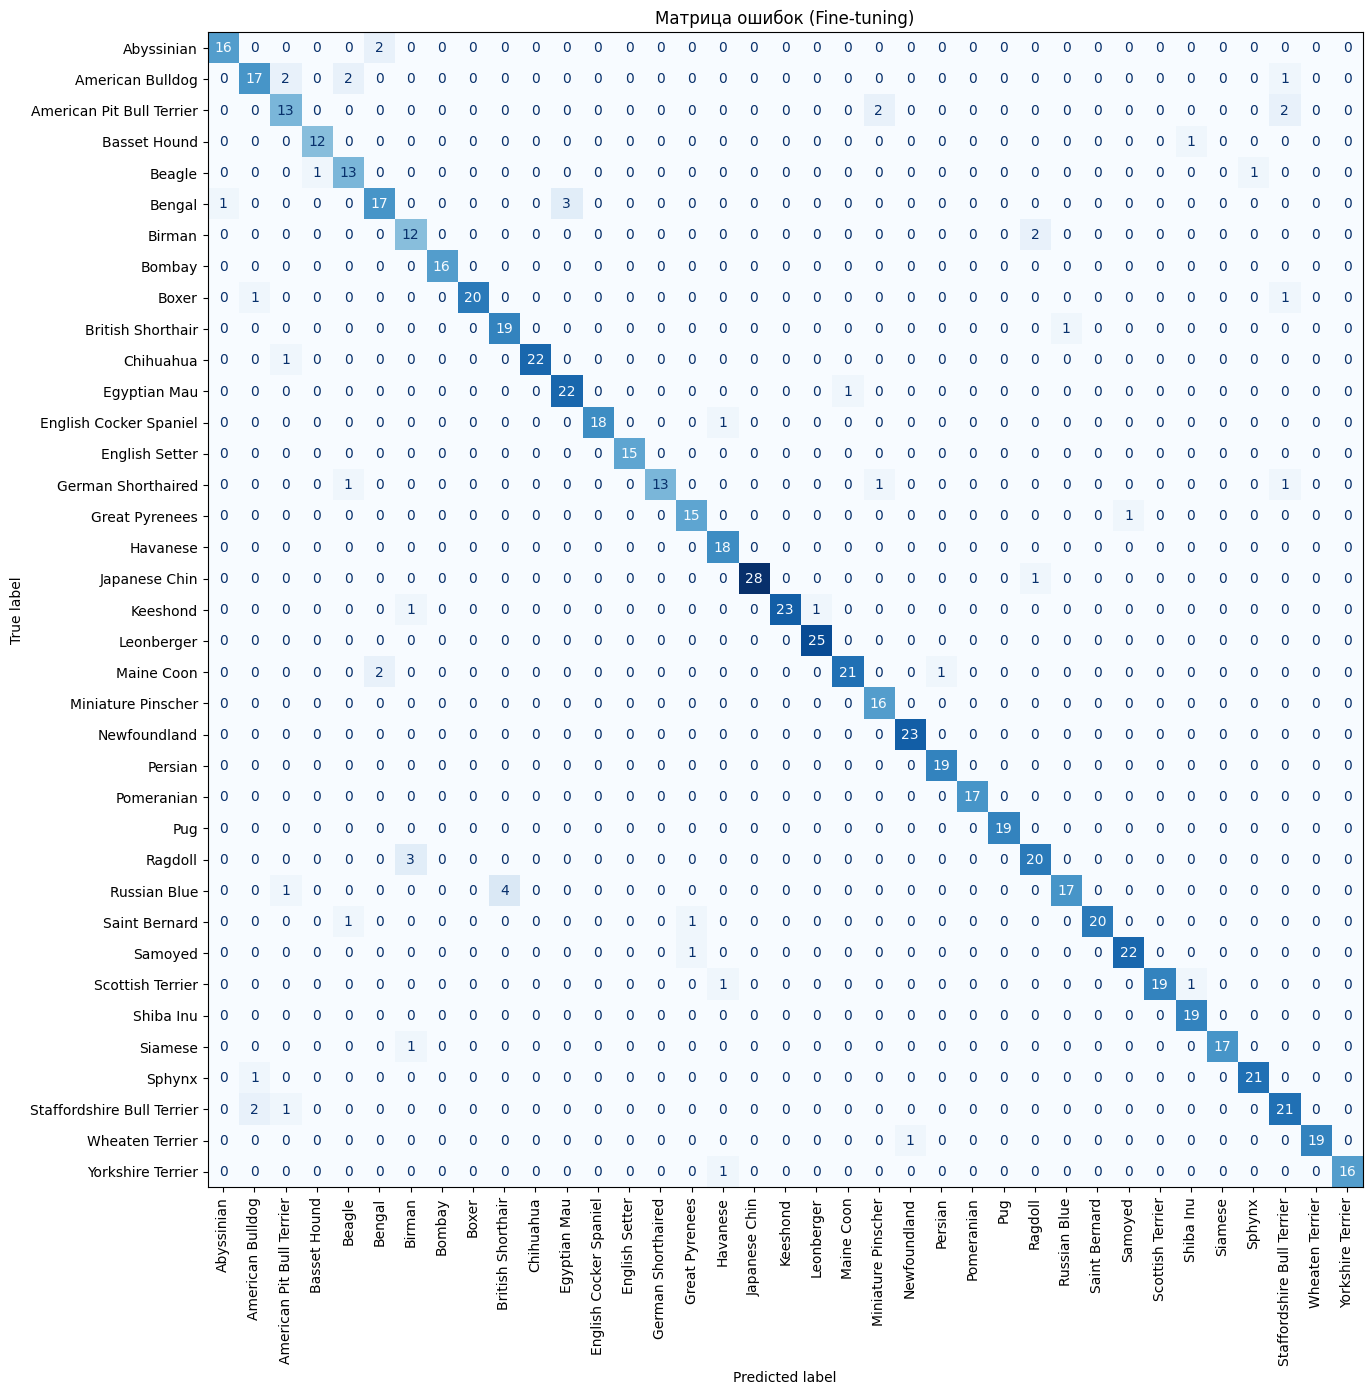


Classification Report (Fine-tuning):

                            precision    recall  f1-score   support

                Abyssinian      0.941     0.889     0.914        18
          American Bulldog      0.810     0.773     0.791        22
 American Pit Bull Terrier      0.722     0.765     0.743        17
              Basset Hound      0.923     0.923     0.923        13
                    Beagle      0.765     0.867     0.812        15
                    Bengal      0.810     0.810     0.810        21
                    Birman      0.706     0.857     0.774        14
                    Bombay      1.000     1.000     1.000        16
                     Boxer      1.000     0.909     0.952        22
         British Shorthair      0.826     0.950     0.884        20
                 Chihuahua      1.000     0.957     0.978        23
              Egyptian Mau      0.880     0.957     0.917        23
    English Cocker Spaniel      1.000     0.947     0.973        19
        

In [17]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Получаем предсказания
model_ft.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for xb, yb in val_dl:
        preds = model_ft(xb.to(device)).argmax(1).cpu().numpy()
        y_pred.extend(preds)
        y_true.extend(yb.numpy())
# Строим матрицу
cm = confusion_matrix(y_true, y_pred)
class_names = val_ds.dataset.classes
fig, ax = plt.subplots(figsize=(15, 15))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=90, colorbar=False)
plt.title("Матрица ошибок (Fine-tuning)")
plt.show()
from sklearn.metrics import classification_report
print("\nClassification Report (Fine-tuning):\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=3, zero_division=0))
# Поиск ТОП-3 пар путаницы
cm_copy = cm.copy()
np.fill_diagonal(cm_copy, 0) # Убираем правильные ответы
# Находим индексы 3-х самых больших значений
top_errors = np.dstack(np.unravel_index(np.argsort(cm_copy.ravel())[::-1], cm_copy.shape))[0][:3]
print("\nТоп-3 пары путаницы:")
for true_idx, pred_idx in top_errors:
    print(f"Истинный: {class_names[true_idx]:15s} | Предсказано: {class_names[pred_idx]:15s} | Ошибок: {cm[true_idx, pred_idx]}")

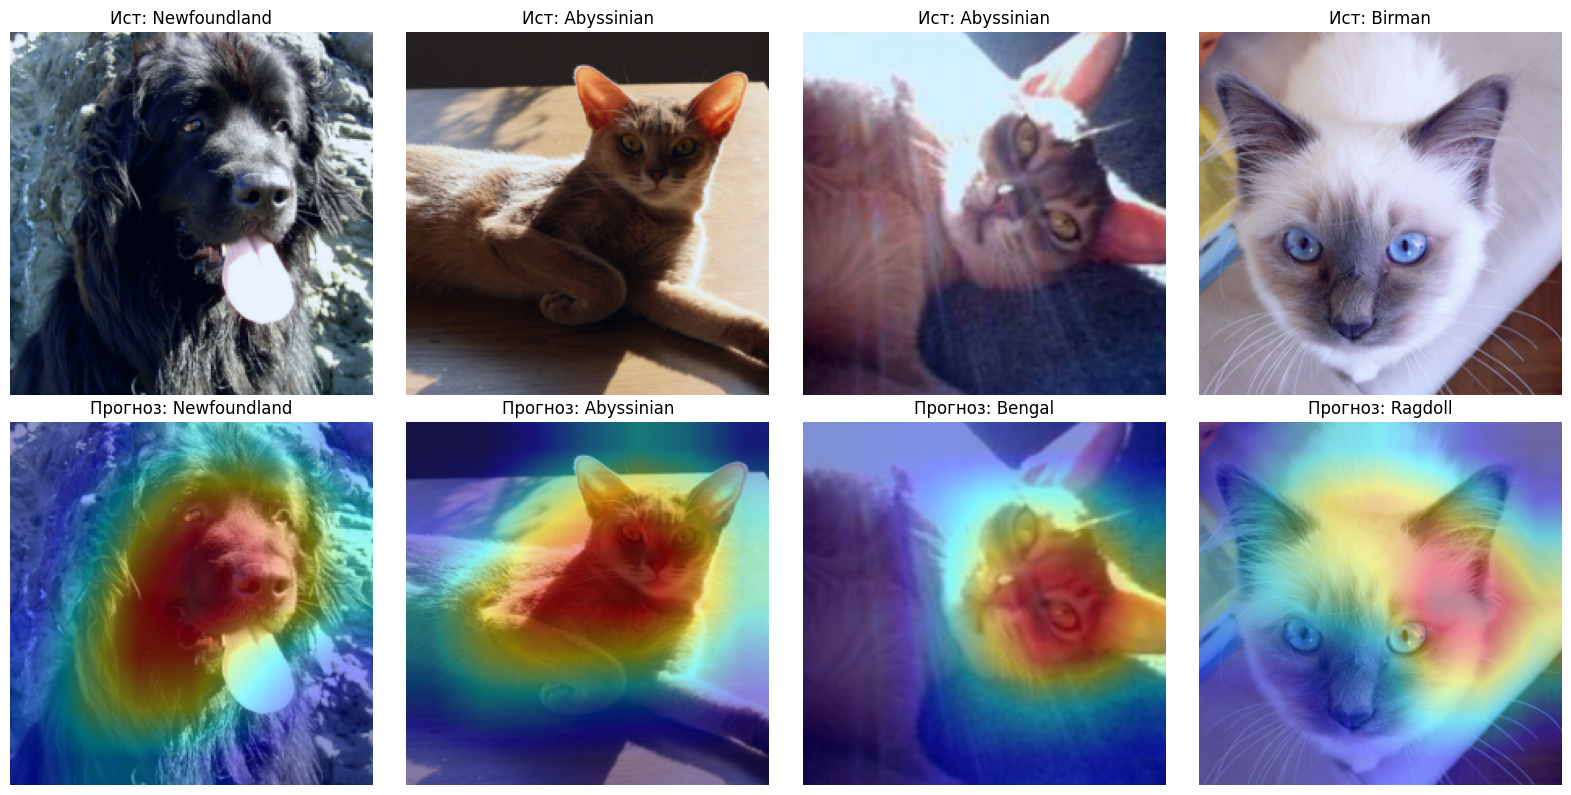

In [18]:
import cv2
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
def get_gradcam(model, img_tensor, target_class):
    model.eval()
    feats, grads = [], []
    def f_hook(m, i, o): feats.append(o)
    def b_hook(m, gi, go): grads.append(go[0])
    target_layer = model.layer4[-1]
    h1 = target_layer.register_forward_hook(f_hook)
    h2 = target_layer.register_full_backward_hook(b_hook)
    out = model(img_tensor)
    model.zero_grad()
    out[0, target_class].backward()
    h1.remove(); h2.remove()
    f_map, g_map = feats[0], grads[0]
    weights = g_map.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * f_map).sum(dim=1)).squeeze().cpu().detach().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cv2.resize(cam, (224, 224))
model_ft.eval()
c_imgs, c_cams, w_imgs, w_cams = [], [], [], []
c_lbls, c_preds, w_lbls, w_preds = [], [], [], []
for xb, yb in val_dl:
    outputs = model_ft(xb.to(device))
    preds = outputs.argmax(dim=1).cpu()
    for i in range(len(yb)):
        img_t = xb[i].unsqueeze(0).to(device)
        cam = get_gradcam(model_ft, img_t, preds[i].item())
        if preds[i] == yb[i] and len(c_imgs) < 2:
            c_imgs.append(xb[i]); c_lbls.append(yb[i].item()); c_preds.append(preds[i].item()); c_cams.append(cam)
        elif preds[i] != yb[i] and len(w_imgs) < 2:
            w_imgs.append(xb[i]); w_lbls.append(yb[i].item()); w_preds.append(preds[i].item()); w_cams.append(cam)
    if len(c_imgs) == 2 and len(w_imgs) == 2: break
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
all_imgs, all_lbls, all_preds, all_cams = c_imgs + w_imgs, c_lbls + w_lbls, c_preds + w_preds, c_cams + w_cams
for i in range(4):
    img = all_imgs[i].permute(1, 2, 0).numpy()
    img = (img - img.min()) / (img.max() - img.min())
    heatmap = cv2.applyColorMap(np.uint8(255 * all_cams[i]), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0
    superimposed = heatmap * 0.4 + img * 0.6
    axes[0, i].imshow(img); axes[0, i].set_title(f"Ист: {class_names[all_lbls[i]]}"); axes[0, i].axis('off')
    axes[1, i].imshow(superimposed); axes[1, i].set_title(f"Прогноз: {class_names[all_preds[i]]}"); axes[1, i].axis('off')
plt.tight_layout(); plt.show()

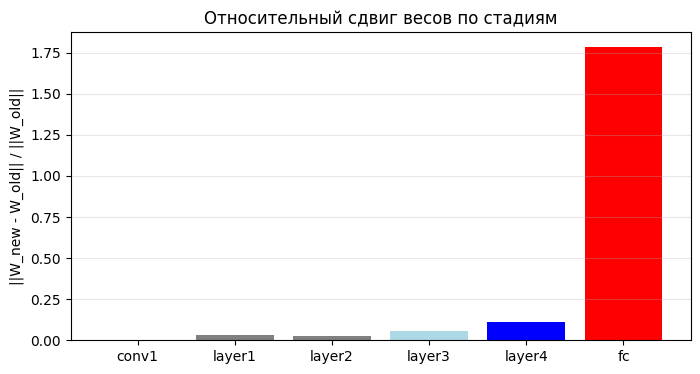

conv1: 0.0000
layer1: 0.0337
layer2: 0.0285
layer3: 0.0538
layer4: 0.1097
fc: 1.7838


In [12]:
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights
import matplotlib.pyplot as plt
def weight_drift(model_before, model_after):
    sd0, sd1 = model_before.state_dict(), model_after.state_dict()
    groups = ['conv1', 'layer1', 'layer2', 'layer3', 'layer4', 'fc']
    drifts = []
    for g in groups:
        num = den = 0.0
        for k in sd0:
            if k.startswith(g) and sd0[k].dtype.is_floating_point:
                num += (sd1[k].cpu() - sd0[k].cpu()).pow(2).sum().item()
                den += sd0[k].cpu().pow(2).sum().item()
        drifts.append((num / den) ** 0.5 if den > 0 else 0)
    return groups, drifts
# Базовая модель для сравнения
ref_model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
ref_model.fc = nn.Linear(512, 37)
groups, drifts = weight_drift(ref_model, model_ft)
# Столбчатая диаграмма
plt.figure(figsize=(8, 4))
plt.bar(groups, drifts, color=['gray', 'gray', 'gray', 'lightblue', 'blue', 'red'])
plt.title('Относительный сдвиг весов по стадиям')
plt.ylabel('||W_new - W_old|| / ||W_old||')
plt.grid(axis='y', alpha=0.3)
plt.show()
for g, d in zip(groups, drifts):
    print(f"{g}: {d:.4f}")

In [13]:
import pandas as pd
import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet18, ResNet18_Weights
# Списки параметров по 13 варианту
wd_list = [0, 1e-5, 1e-4, 1e-2]
dropout_list = [0, 0.3, 0.5]
label_smooth = 0.1
results = []
print("Начинаем решетку 4x3...")
for wd in wd_list:
    for drop in dropout_list:
        # 1. Создаем модель и меняем голову с учетом Dropout
        model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        in_feat = model.fc.in_features
        if drop > 0:
            model.fc = nn.Sequential(nn.Dropout(drop), nn.Linear(in_feat, 37))
        else:
            model.fc = nn.Linear(in_feat, 37)
        model = model.to(device)
        # 2. Замораживаем всё, размораживаем layer3, layer4, fc
        for p in model.parameters(): p.requires_grad = False
        for name, child in model.named_children():
            if name in ['layer3', 'layer4', 'fc']:
                for p in child.parameters(): p.requires_grad = True
        # 3. Оптимизатор с текущим weight_decay
        optimizer = optim.AdamW([
            {'params': model.layer3.parameters(), 'lr': 5e-5},
            {'params': model.layer4.parameters(), 'lr': 1e-4},
            {'params': model.fc.parameters(),     'lr': 5e-4}
        ], weight_decay=wd)
        # 4. Функция потерь с Label Smoothing
        criterion_ls = nn.CrossEntropyLoss(label_smoothing=label_smooth)
        # 5. Обучаем 3 эпохи (для выявления тренда)
        for epoch in range(3):
            train_epoch(model, train_dl, optimizer, criterion_ls)
        # 6. Оцениваем на валидации
        _, val_acc = evaluate(model, val_dl, criterion_ls)
        print(f"wd={wd:<8} | dropout={drop:<4} | Val Acc: {val_acc:.4f}")
        results.append({
            'weight_decay': wd,
            'dropout': drop,
            'label_smoothing': label_smooth,
            'val_accuracy': round(val_acc, 4)
        })
# Вывод таблицы
df = pd.DataFrame(results)
print("\nСводная таблица результатов:")
display(df)

Начинаем решетку 4x3...
wd=0        | dropout=0    | Val Acc: 0.9022
wd=0        | dropout=0.3  | Val Acc: 0.9158
wd=0        | dropout=0.5  | Val Acc: 0.9035
wd=1e-05    | dropout=0    | Val Acc: 0.9185
wd=1e-05    | dropout=0.3  | Val Acc: 0.9035
wd=1e-05    | dropout=0.5  | Val Acc: 0.9035
wd=0.0001   | dropout=0    | Val Acc: 0.9103
wd=0.0001   | dropout=0.3  | Val Acc: 0.9171
wd=0.0001   | dropout=0.5  | Val Acc: 0.9062
wd=0.01     | dropout=0    | Val Acc: 0.8886
wd=0.01     | dropout=0.3  | Val Acc: 0.9076
wd=0.01     | dropout=0.5  | Val Acc: 0.9035

Сводная таблица результатов:


,weight_decay,dropout,label_smoothing,val_accuracy
0,0.00000,0.0,0.1,0.9022
1,0.00000,0.3,0.1,0.9158
2,0.00000,0.5,0.1,0.9035
3,0.00001,0.0,0.1,0.9185
4,0.00001,0.3,0.1,0.9035
5,0.00001,0.5,0.1,0.9035
6,0.00010,0.0,0.1,0.9103
7,0.00010,0.3,0.1,0.9171
8,0.00010,0.5,0.1,0.9062
9,0.01000,0.0,0.1,0.8886


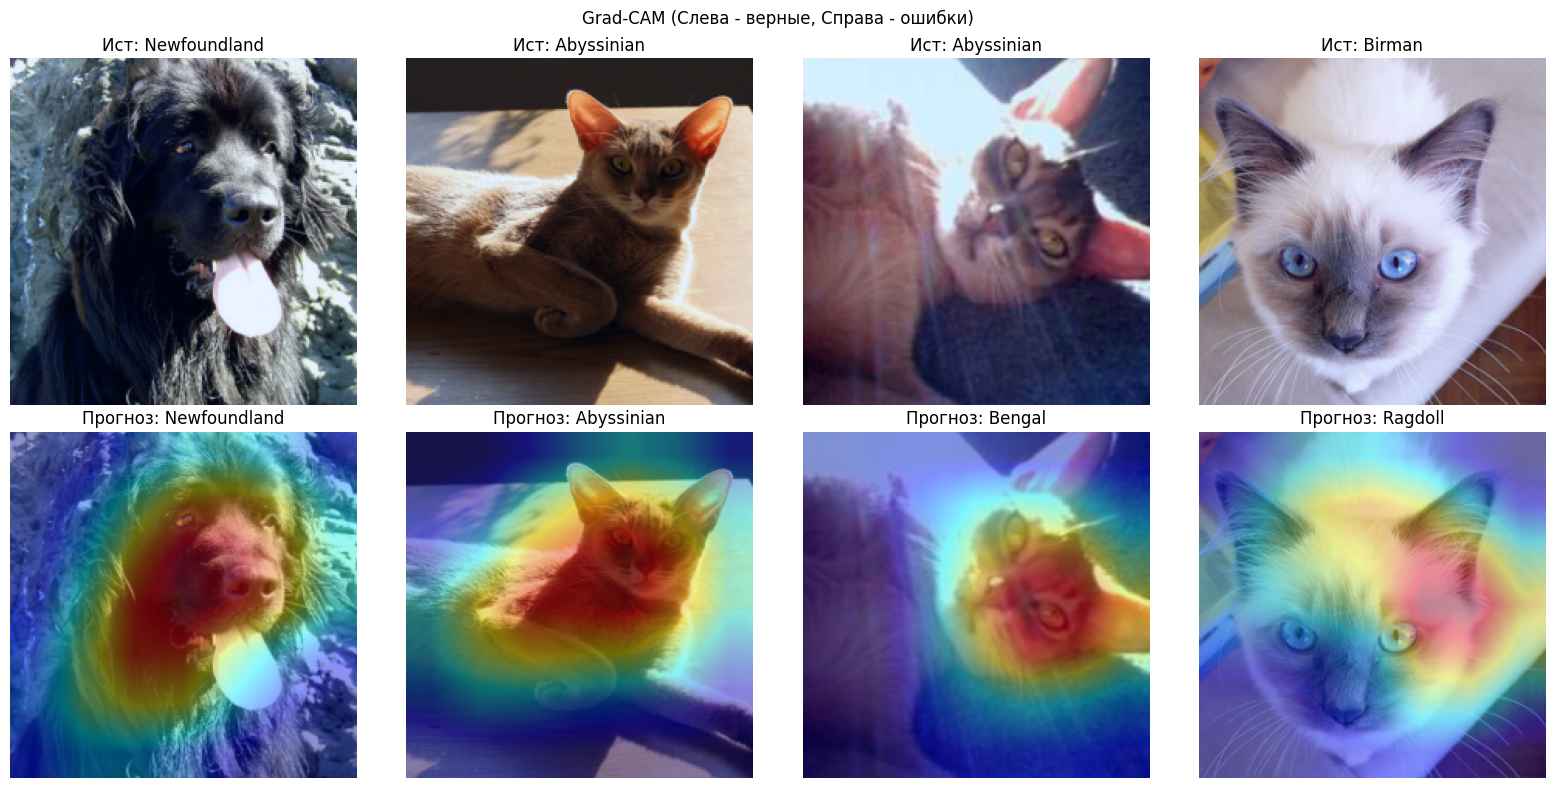

In [14]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import cv2
def get_gradcam(model, img_tensor, target_class):
    model.eval()
    feats, grads = [], []
    def f_hook(m, i, o): feats.append(o)
    def b_hook(m, gi, go): grads.append(go[0])
    # Вешаем хуки на последний сверточный слой
    target_layer = model.layer4[-1]
    h1 = target_layer.register_forward_hook(f_hook)
    h2 = target_layer.register_full_backward_hook(b_hook)
    out = model(img_tensor)
    model.zero_grad()
    out[0, target_class].backward()
    h1.remove()
    h2.remove()
    # Считаем карту
    f_map, g_map = feats[0], grads[0]
    weights = g_map.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * f_map).sum(dim=1)).squeeze().cpu().detach().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cv2.resize(cam, (224, 224))
# Ищем картинки
model_ft.eval()
c_imgs, c_lbls, c_preds, c_cams = [], [], [], []
w_imgs, w_lbls, w_preds, w_cams = [], [], [], []
for xb, yb in val_dl:
    outputs = model_ft(xb.to(device))
    preds = outputs.argmax(dim=1).cpu()
    for i in range(len(yb)):
        img_t = xb[i].unsqueeze(0).to(device)
        cam = get_gradcam(model_ft, img_t, preds[i].item())
        if preds[i] == yb[i] and len(c_imgs) < 2:
            c_imgs.append(xb[i]); c_lbls.append(yb[i].item()); c_preds.append(preds[i].item()); c_cams.append(cam)
        elif preds[i] != yb[i] and len(w_imgs) < 2:
            w_imgs.append(xb[i]); w_lbls.append(yb[i].item()); w_preds.append(preds[i].item()); w_cams.append(cam)
    if len(c_imgs) == 2 and len(w_imgs) == 2: break
# Отрисовка
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
all_imgs = c_imgs + w_imgs
all_lbls = c_lbls + w_lbls
all_preds = c_preds + w_preds
all_cams = c_cams + w_cams
class_names = val_ds.dataset.classes
for i in range(4):
    img = all_imgs[i].permute(1, 2, 0).numpy()
    img = (img - img.min()) / (img.max() - img.min())
    heatmap = cv2.applyColorMap(np.uint8(255 * all_cams[i]), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0
    superimposed = heatmap * 0.4 + img * 0.6
    axes[0, i].imshow(img); axes[0, i].set_title(f"Ист: {class_names[all_lbls[i]]}"); axes[0, i].axis('off')
    axes[1, i].imshow(superimposed); axes[1, i].set_title(f"Прогноз: {class_names[all_preds[i]]}"); axes[1, i].axis('off')
plt.suptitle("Grad-CAM (Слева - верные, Справа - ошибки)")
plt.tight_layout()
plt.show()

In [15]:
import torch
import torch.nn.functional as F
# 1. Обычная проверка
model_ft.eval()
correct_normal = 0
total = 0
with torch.no_grad():
    for xb, yb in val_dl:
        xb, yb = xb.to(device), yb.to(device)
        preds = model_ft(xb).argmax(1)
        correct_normal += (preds == yb).sum().item()
        total += yb.size(0)
acc_normal = correct_normal / total
print(f"Точность без TTA: {acc_normal:.4f}")
# 2. Проверка с TTA
correct_tta = 0
with torch.no_grad():
    for xb, yb in val_dl:
        xb, yb = xb.to(device), yb.to(device)
        # Предсказание 1: Оригинал
        out = F.softmax(model_ft(xb), dim=1)
        # Предсказание 2: Отражение по горизонтали
        out += F.softmax(model_ft(torch.flip(xb, dims=[3])), dim=1)
        # Предсказание 3: Отражение по вертикали
        out += F.softmax(model_ft(torch.flip(xb, dims=[2])), dim=1)
        # Предсказание 4: Отражение по обеим осям
        out += F.softmax(model_ft(torch.flip(xb, dims=[2, 3])), dim=1)
        out_avg = out / 4.0
        preds = out_avg.argmax(1)
        correct_tta += (preds == yb).sum().item()
acc_tta = correct_tta / total
print(f"Точность с TTA:    {acc_tta:.4f}")
print(f"Прирост:          {100 * (acc_tta - acc_normal):+.2f}%")

Точность без TTA: 0.9239
Точность с TTA:    0.9022
Прирост:          -2.17%
